# L7 · LangGraph: estado, nodos y aristas

*Advanced Topics in Analytics II - Generative AI* · Instructor: Sergio A. Mora Pardo

Hasta ahora `create_agent` decidía el flujo por nosotros: modelo, herramienta, modelo. Desde esta semana armamos el flujo **a mano** con LangGraph. Un grafo tiene tres piezas:

- **Estado**: un diccionario con los datos que comparten todos los pasos. Aquí, un ticket de soporte de **ACME**.
- **Nodos**: funciones que reciben el estado y devuelven **solo lo que cambian**.
- **Aristas**: el orden en que se ejecutan los nodos.

Este notebook **no llama a ningún modelo**: los nodos son funciones normales de Python. Así se ve la mecánica sin ruido. En [L8](L8-LangGraphMessages.ipynb) entra el modelo.

## Objetivos

1. Definir el estado de un grafo con `TypedDict`.
2. Escribir nodos que devuelven actualizaciones parciales.
3. Conectar nodos con `add_edge` y `add_sequence`, compilar y ejecutar.
4. Combinar actualizaciones con un **reducer**.
5. Seguir la ejecución paso a paso con `stream`.

## 1. El estado

El estado es la «memoria compartida» del grafo. `TypedDict` declara qué campos tiene y de qué tipo. Un ticket nuevo llega solo con el cliente y el mensaje; los demás campos los llenan los nodos.

In [1]:
from typing import TypedDict


class TicketState(TypedDict, total=False):
    customer: str
    message: str
    category: str
    priority: str

## 2. Nodos: devuelven solo lo que cambian

Un nodo recibe **todo** el estado y devuelve un diccionario con **los campos que actualiza**. LangGraph mezcla esa respuesta con el estado anterior: los campos que el nodo no menciona se conservan.

Aquí clasificamos con reglas simples, sin modelo: palabras clave para la categoría y la mora para la prioridad.

In [2]:
def classify(state: TicketState) -> dict:
    text = state["message"].lower()
    if "mora" in text or "atrasad" in text:
        category = "cobranza"
    elif "desembolso" in text or "no me llega" in text:
        category = "desembolso"
    else:
        category = "otro"
    return {"category": category}


def prioritize(state: TicketState) -> dict:
    return {"priority": "alta" if state["category"] == "cobranza" else "normal"}

## 3. Aristas: el orden

`StateGraph(TicketState)` crea el grafo; `add_node` registra cada nodo y `add_edge` dice qué sigue. `START` y `END` marcan la entrada y la salida. `compile()` revisa que todo esté conectado y devuelve un *runnable*: se usa con `invoke`, como una cadena de L1.

In [3]:
from IPython.display import Image, display


def show(graph):
    """Dibuja el grafo como imagen con el servicio mermaid.ink (necesita conexión a internet)."""
    display(Image(graph.get_graph().draw_mermaid_png()))

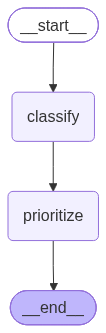

In [4]:
from langgraph.graph import END, START, StateGraph

builder = StateGraph(TicketState)
builder.add_node("classify", classify)
builder.add_node("prioritize", prioritize)
builder.add_edge(START, "classify")
builder.add_edge("classify", "prioritize")
builder.add_edge("prioritize", END)

graph = builder.compile()
show(graph)

In [5]:
graph.invoke({"customer": "C-3307", "message": "Tengo 75 días de mora, ¿qué hago?"})

{'customer': 'C-3307',
 'message': 'Tengo 75 días de mora, ¿qué hago?',
 'category': 'cobranza',
 'priority': 'alta'}

El resultado es el estado final: los dos campos de entrada más los que llenaron los nodos. Cuando los pasos van en fila, `add_sequence` escribe las mismas aristas en una línea:

In [6]:
builder = StateGraph(TicketState)
builder.add_sequence([classify, prioritize])
builder.add_edge(START, "classify")
sequence_graph = builder.compile()

sequence_graph.invoke({"customer": "C-2210", "message": "Firmé hace una hora y no me llega el desembolso."})

{'customer': 'C-2210',
 'message': 'Firmé hace una hora y no me llega el desembolso.',
 'category': 'desembolso',
 'priority': 'normal'}

## 4. Reducers: combinar en lugar de reemplazar

Por defecto, si un nodo devuelve un campo, **reemplaza** su valor. A veces queremos **acumular**: por ejemplo, una bitácora donde cada paso deja una nota. Un **reducer** dice cómo combinar el valor viejo con el nuevo. Con `Annotated[list[str], operator.add]`, las listas se **concatenan**.

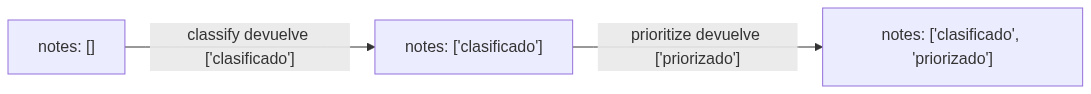

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    S0["notes: []"] -->|"classify devuelve ['clasificado']"| S1["notes: ['clasificado']"]
    S1 -->|"prioritize devuelve ['priorizado']"| S2["notes: ['clasificado', 'priorizado']"]
```

</details>

In [7]:
import operator
from typing import Annotated


class LoggedState(TicketState, total=False):
    notes: Annotated[list[str], operator.add]


def classify_logged(state: LoggedState) -> dict:
    return classify(state) | {"notes": ["clasificado por palabras clave"]}


def prioritize_logged(state: LoggedState) -> dict:
    update = prioritize({**state, **classify(state)})
    return update | {"notes": [f"prioridad {update['priority']}"]}


builder = StateGraph(LoggedState)
builder.add_sequence([classify_logged, prioritize_logged])
builder.add_edge(START, "classify_logged")
logged_graph = builder.compile()

logged_graph.invoke({"customer": "C-3307", "message": "Estoy atrasado en mi crédito", "notes": ["recibido"]})

{'customer': 'C-3307',
 'message': 'Estoy atrasado en mi crédito',
 'category': 'cobranza',
 'priority': 'alta',
 'notes': ['recibido', 'clasificado por palabras clave', 'prioridad alta']}

La nota inicial, `"recibido"`, se conserva: cada nodo **añade** a la lista. Sin el reducer, la última nota reemplazaría a todas las anteriores. En L8 usaremos el reducer más común de LangGraph: el que acumula los mensajes de una conversación.

## 5. Seguir la ejecución con `stream`

`stream(..., stream_mode="updates")` devuelve lo que cambió **cada nodo**, en orden. Es la forma de depurar un grafo: ver qué escribió cada paso.

In [8]:
for step in logged_graph.stream(
    {"customer": "C-2210", "message": "No me llega el desembolso", "notes": []}, stream_mode="updates"
):
    print(step)

{'classify_logged': {'category': 'desembolso', 'notes': ['clasificado por palabras clave']}}
{'prioritize_logged': {'priority': 'normal', 'notes': ['prioridad normal']}}


## Práctica breve

1. Añade un nodo `assign_team` que llene un campo `team` según la categoría, y conéctalo después de `prioritize`.
2. Cambia el reducer de `notes` por uno que se quede solo con las 2 últimas notas. ¿Cómo lo escribirías?
3. Usa `stream_mode="values"` en la sección 5. ¿Qué diferencia hay con `"updates"`?

## Referencias

- [Grafos en LangGraph](https://docs.langchain.com/oss/python/langgraph/graph-api) · [Reducers](https://docs.langchain.com/oss/python/langgraph/graph-api#reducers)
- **Learning LangChain**, capítulo 5: [`a-chatbot.py`](https://github.com/langchain-ai/learning-langchain/blob/master/ch5/py/a-chatbot.py)